In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Step 1: Given dataset
data = np.array([
    [5.0, 4.8],
    [1.0, 1.4],
    [4.4, 5.8],
    [3.8, 4.4],
    [6.2, 6.0],
    [4.6, 5.4],
    [4.0, 3.2],
    [2.0, 2.2],
    [3.0, 3.2],
    [2.2, 1.8]
])

In [3]:
# Extract x and y values
x = data[:, 0]
y = data[:, 1]

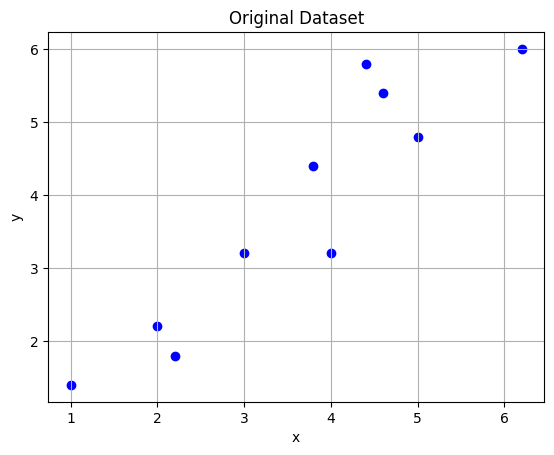

In [4]:
# Step 1: Visualize the dataset using a scatter plot
plt.scatter(x, y, color='blue')
plt.title('Original Dataset')
plt.xlabel('x')
plt.ylabel('y')
plt.grid(True)
plt.show()

In [5]:
# Step 2: Normalize the data by subtracting the mean
mean_x = np.mean(x)
mean_y = np.mean(y)
normalized_x = x - mean_x
normalized_y = y - mean_y
normalized_data = np.column_stack((normalized_x, normalized_y))


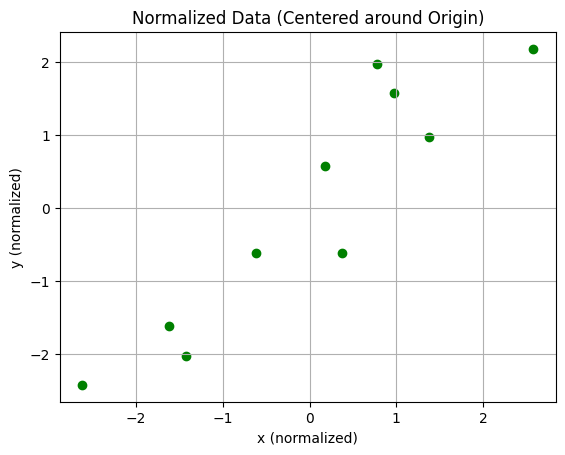

In [6]:
# Plot the normalized data
plt.scatter(normalized_x, normalized_y, color='green')
plt.title('Normalized Data (Centered around Origin)')
plt.xlabel('x (normalized)')
plt.ylabel('y (normalized)')
plt.grid(True)
plt.show()

In [7]:
# Step 3: Compute the covariance matrix of the normalized dataset
cov_matrix = np.cov(normalized_data, rowvar=False)
print("Covariance Matrix:")
print(cov_matrix)

Covariance Matrix:
[[2.46622222 2.46177778]
 [2.46177778 2.86622222]]


In [9]:
# Step 4: Calculate the eigenvalues and eigenvectors of the covariance matrix
eigenvalues, eigenvectors = np.linalg.eig(cov_matrix)
print("Eigenvalues:")
print(eigenvalues)
print("Eigenvectors:")
print(eigenvectors)

Eigenvalues:
[0.1963336  5.13611085]
Eigenvectors:
[[-0.73517866 -0.6778734 ]
 [ 0.6778734  -0.73517866]]


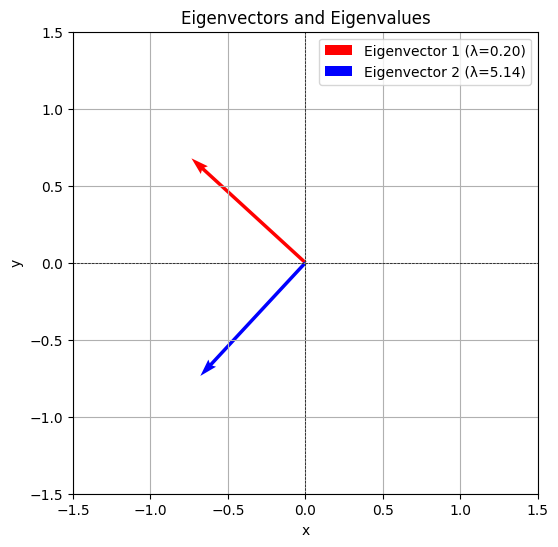

In [10]:
# Plot eigenvalues and eigenvectors
plt.figure(figsize=(6, 6))
origin = np.array([0, 0])
plt.quiver(*origin, eigenvectors[0, 0], eigenvectors[1, 0], angles='xy', scale_units='xy', scale=1, color='r', label=f'Eigenvector 1 (λ={eigenvalues[0]:.2f})')
plt.quiver(*origin, eigenvectors[0, 1], eigenvectors[1, 1], angles='xy', scale_units='xy', scale=1, color='b', label=f'Eigenvector 2 (λ={eigenvalues[1]:.2f})')
plt.xlim(-1.5, 1.5)
plt.ylim(-1.5, 1.5)
plt.axhline(0, color='black', linestyle='--', linewidth=0.5)
plt.axvline(0, color='black', linestyle='--', linewidth=0.5)
plt.title('Eigenvectors and Eigenvalues')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.grid(True)
plt.show()

In [11]:
# Step 5: Select the principal component corresponding to the largest eigenvalue
principal_component = eigenvectors[:, np.argmax(eigenvalues)]
print("Principal Component (Eigenvector corresponding to the largest eigenvalue):")
print(principal_component)

Principal Component (Eigenvector corresponding to the largest eigenvalue):
[-0.6778734  -0.73517866]


In [12]:
# Transform the data into a lower-dimensional space with one principal component
transformed_data = np.dot(normalized_data, principal_component)
print(transformed_data)

[-1.65594037  3.55516065 -1.98439499 -0.54842083 -3.35160284 -1.82589821
  0.19821887  2.28914433  0.87609227  2.44764111]


In [13]:
# Step 6: Project the transformed data back onto the original space
reconstructed_data = np.outer(transformed_data, principal_component)
reconstructed_data[:, 0] += mean_x
reconstructed_data[:, 1] += mean_y
print(reconstructed_data)

[[4.74251793 5.03741202]
 [1.21005117 1.20632177]
 [4.96516858 5.27888484]
 [3.99175989 4.22318729]
 [5.89196241 6.28402687]
 [4.85772782 5.16236139]
 [3.4856327  3.67427371]
 [2.06824995 2.13706995]
 [3.02612035 3.17591566]
 [1.9608092  2.0205465 ]]


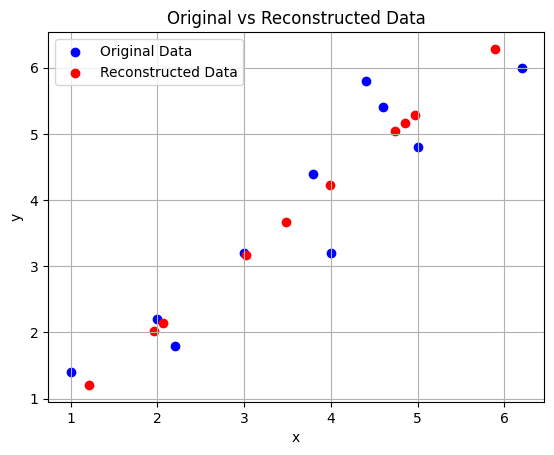

In [14]:
# Step 7: Plot the reconstructed data and compare it with the original dataset
plt.scatter(x, y, color='blue', label='Original Data')
plt.scatter(reconstructed_data[:, 0], reconstructed_data[:, 1], color='red', label='Reconstructed Data')
plt.title('Original vs Reconstructed Data')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.grid(True)
plt.show()